# 第7回 予算最適化 ― 同じ総額で、売上を増やす配分を探す

**使い方**：上のセルから順に `Shift + Enter` で実行していきます。コードを書き換える必要はありません。
「🧪 実験」のセルだけは、値を変えて何度か実行してみてください。

**この回のゴール**

1. 予算最適化の原理（限界ROASをそろえる）を、2チャネルの例で理解する
2. 7チャネルの最適な配分を、制約つきで計算する
3. 「最適化したら売上がどれだけ増えるか」を、確かさと一緒に出す
4. 配分案を、予算を決める人にどう提案するかを考える

**所要時間**：60分ほど。重い計算はありません（いちばん長いセルで20秒ほど）。

**前提**：第4回で保存した学習結果（`mmm_cs1.nc`）を使います。まだ無いときは、この回の中で学習します（3〜13分）。

> **この教材について**
>
> - PyMC-Marketing の公式ケーススタディ「[MMM End-to-End Case Study](https://www.pymc-marketing.io/en/stable/notebooks/mmm/mmm_case_study.html)」を、日本語で順に学べるように組み立て直した教材です（作成：Birdwing Technologies合同会社）。
> - コードは本家（Apache License 2.0）をもとに改変しています。解説・図・小課題は独自に加えたものです。
> - データは本家と同じ、公開されている学習用のデータです。
> - 解説ページと全体の目次：<https://bwtech.co.jp/learn/mmm/07-budget-optimization>

## 0. 準備

最初のセルは、どの回にも共通の準備です。**Google Colab でも、自分のPCでも、そのまま実行できます。**

- データがなければダウンロードします（約80KB）
- グラフに日本語を表示できるようにします
- Google Colab のときだけ、必要なライブラリを入れます（数分かかります）
- 学習結果の置き場所を決めます（Colab のときは Google ドライブ。初回に許可の画面が出ます）

In [1]:
# ===== 共通の準備（Google Colab でも、自分のPCでも、このまま実行できます） =====
import subprocess, sys, urllib.request
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# --- g++（計算を速くする部品）がない環境では、その旨を PyTensor に伝える（WARNING が短くなる） ---
import os, shutil
if shutil.which("g++") is None:
    os.environ["PYTENSOR_FLAGS"] = "cxx="

# --- Colab のときだけ、ライブラリを入れる（数分かかります） ---
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pymc-marketing==0.19.2", "nutpie==0.16.8"], check=True)

# --- ファイルの置き場所 ---
BASE_DIR = Path("/content/mmm-pymc") if IN_COLAB else Path.cwd()
DATA_PATH = BASE_DIR / "data" / "case_study_data.csv"

# --- 学習結果の置き場所 ---
# Colab は接続が切れるとファイルが消えるので、学習結果は Google ドライブに置く（初回に許可の画面が出ます）。
# ドライブを使いたくないときは USE_DRIVE = False にする（その場合は、回ごとに学習し直します）。
USE_DRIVE = True
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    MODEL_DIR = Path("/content/drive/MyDrive/mmm-pymc/models")
else:
    MODEL_DIR = BASE_DIR / "models"
MODEL_PATH = MODEL_DIR / "mmm_cs1.nc"

# --- データの取得（なければダウンロードする） ---
DATA_URL = "https://raw.githubusercontent.com/pymc-labs/pymc-marketing/0.19.2/data/case_study_data.csv"
if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

# --- グラフの日本語フォント ---
import matplotlib.pyplot as plt
from matplotlib import font_manager

def setup_japanese_font():
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in ["Meiryo", "Yu Gothic", "Hiragino Sans", "Noto Sans CJK JP", "IPAexGothic", "IPAGothic"]:
        if name in installed:
            plt.rcParams["font.family"] = name
            return name
    # 日本語フォントが見つからないとき（Colab など）は、フォント入りのパッケージを入れる
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "matplotlib-fontja"], check=True)
    import matplotlib_fontja  # 読み込むだけで日本語フォント（IPAexGothic）が設定される
    return "IPAexGothic"

font_name = setup_japanese_font()
plt.rcParams["axes.unicode_minus"] = False    # マイナス記号の文字化けを防ぐ

print("実行環境:", "Google Colab" if IN_COLAB else "自分のPC")
print("データ:", DATA_PATH.relative_to(BASE_DIR).as_posix(), "（取得済み）")
print("日本語フォント:", font_name)

実行環境: 自分のPC
データ: data/case_study_data.csv （取得済み）
日本語フォント: Meiryo


この回で使うライブラリを読み込みます。

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from pymc_marketing.mmm.multidimensional import MMM

SEED = 42
FAST = {"mode": "NUMBA"}


WARNING (pytensor.configdefaults): g++ not available, if using conda: `conda install gxx`


### 学習結果を読み込む

第4回で保存した学習結果（`mmm_cs1.nc`）を読み込みます。

- 見つかったとき → 読み込むだけ（数秒）
- 見つからないとき → 第4回と同じ設定で、この場で学習して保存します（**3〜13分**）

In [3]:
def load_or_fit_model():
    """学習結果を読み込む。なければ、第4回と同じ設定で学習して保存する。"""
    if MODEL_PATH.exists():
        print("保存済みの学習結果を読み込みました:", MODEL_PATH.name)
        return MMM.load(str(MODEL_PATH))

    print("学習結果が見つからないので、第4回と同じ設定で学習します（3〜13分）。")
    from pymc_extras.prior import Prior
    from pymc_marketing.mmm import GeometricAdstock, LogisticSaturation

    raw = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])
    names = {
        "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
        "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
    }
    channels = list(names.values())
    controls = [c for c in raw.columns if c.startswith("hldy_")]
    data = raw[["wk_strt_dt", "sales", *names.keys(), *controls]].rename(columns=names)
    train = data[data["wk_strt_dt"] <= pd.to_datetime("2018-02-01")]
    X_tr, y_tr = train.drop(columns="sales"), train["sales"]
    share = X_tr[channels].sum() / X_tr[channels].sum().sum()

    model = MMM(
        model_config={
            "intercept": Prior("Normal", mu=0.2, sigma=0.05),
            "saturation_beta": Prior("HalfNormal", sigma=share[channels].to_numpy(), dims="channel"),
            "gamma_control": Prior("Normal", mu=0, sigma=1, dims="control"),
            "gamma_fourier": Prior("Laplace", mu=0, b=1, dims="fourier_mode"),
            "likelihood": Prior("TruncatedNormal", lower=0, sigma=Prior("HalfNormal", sigma=1)),
        },
        date_column="wk_strt_dt", target_column="sales",
        channel_columns=channels, control_columns=controls,
        adstock=GeometricAdstock(l_max=6), saturation=LogisticSaturation(), yearly_seasonality=5,
    )
    model.build_model(X_tr, y_tr)
    model.add_original_scale_contribution_variable(
        var=["channel_contribution", "control_contribution", "intercept_contribution",
             "yearly_seasonality_contribution", "y"]
    )
    model.fit(X_tr, y_tr, chains=4, tune=1_000, draws=1_000, target_accept=0.9,
              nuts_sampler="nutpie", random_seed=42)
    model.sample_posterior_predictive(X_tr, extend_idata=True, combined=True, random_seed=42,
                                      compile_kwargs={"mode": "NUMBA"})
    for group in ["warmup_posterior", "warmup_sample_stats"]:
        if group in model.idata.groups():
            del model.idata[group]
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    model.save(str(MODEL_PATH))
    return model

mmm = load_or_fit_model()
posterior = mmm.idata["posterior"]
const = mmm.idata["constant_data"]


保存済みの学習結果を読み込みました: mmm_cs1.nc


In [4]:
raw_df = pd.read_csv(DATA_PATH, parse_dates=["wk_strt_dt"])

channel_names = {
    "mdsp_dm": "DM", "mdsp_inst": "折込", "mdsp_nsp": "新聞", "mdsp_audtr": "ラジオ",
    "mdsp_vidtr": "TV", "mdsp_so": "ソーシャル", "mdsp_on": "ディスプレイ",
}
channels = list(channel_names.values())
control_columns = [c for c in raw_df.columns if c.startswith("hldy_")]
date_column, target_column = "wk_strt_dt", "sales"

data_df = raw_df[[date_column, target_column, *channel_names.keys(), *control_columns]].rename(columns=channel_names)
split_date = pd.to_datetime("2018-02-01")
train_df = data_df[data_df[date_column] <= split_date]
test_df = data_df[data_df[date_column] > split_date]
X_train = train_df.drop(columns=target_column)
print(f"学習用: {len(train_df)} 週 / テスト用: {len(test_df)} 週")

学習用: 183 週 / テスト用: 26 週


### 材料：飽和曲線の関数

第5回の4章で、「毎週 $x$ の広告費を出し続けたときの週あたりの貢献」は次の式で計算できることを確かめました。

$$
\text{週あたりの貢献}_c(x) \;=\; \beta_c \cdot S\!\left(\lambda_c \cdot \frac{x}{\text{最大費用}_c}\right) \times \text{最大売上}
$$

この回は、この式を何度も使います。4,000組のパラメータを、計算しやすい形（4,000行 × 7列の表）にしておきます。

In [5]:
S = ("chain", "draw")
beta = posterior["saturation_beta"].sel(channel=channels).stack(s=S).transpose("s", "channel").to_numpy()   # 4,000 × 7
lam = posterior["saturation_lam"].sel(channel=channels).stack(s=S).transpose("s", "channel").to_numpy()     # 4,000 × 7
channel_scale = const["channel_scale"].sel(channel=channels).to_numpy()     # チャネルごとの最大費用
target_scale = float(const["target_scale"].values[0])                       # 最大売上

def weekly_contribution(x):
    # x：7チャネルの週の広告費 → 週あたりの貢献（4,000組 × 7チャネル）
    u = lam * np.asarray(x) / channel_scale
    return beta * (1 - np.exp(-u)) / (1 + np.exp(-u)) * target_scale

def marginal_roas(x):
    # x の水準から広告費を少し増やしたときの、追加1あたりの売上（4,000組 × 7チャネル）
    u = lam * np.asarray(x) / channel_scale
    return beta * lam / channel_scale * 2 * np.exp(-u) / (1 + np.exp(-u)) ** 2 * target_scale

def expected_total(x):
    # 7チャネル合計の週あたりの貢献を、4,000組で平均したもの（＝期待値）
    return weekly_contribution(x).sum(axis=1).mean()

print(beta.shape, lam.shape)

(4000, 7) (4000, 7)


## 1. 予算最適化の原理

### 1-1. 問いの立て方

予算最適化の問いは、こうです。

> **広告費の総額は変えずに、チャネル間の配分だけを変えて、売上（広告の貢献の合計）をいちばん大きくするには？**

総額を増やせば売上が増えるのは当たり前です。「同じお金で、もっとうまく使えないか」を考えます。

### 1-2. 2チャネルで考える

まずディスプレイと折込の2つだけで考えます。テスト期間（直近26週）の週平均は、ディスプレイが約25万、折込が約4万です。
この合計（約29万）を変えずに、ディスプレイから折込へ少しずつ移していきます。

いまの限界ROAS：ディスプレイ 41.6、折込 57.8
最大になる点：7.8万を移す → 限界ROAS は ディスプレイ 49.6、折込 49.4
2チャネルの貢献の合計：0.1579億／週 → 0.1644億／週（+4.2%）


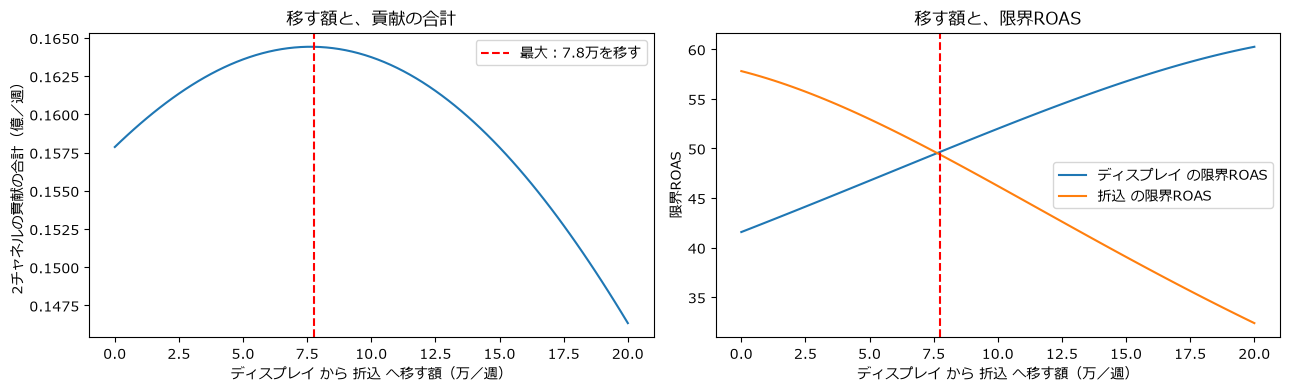

In [6]:
x_now = test_df[channels].mean().to_numpy()          # テスト期間の週平均費用（7チャネル）

def move_budget(src, dst, moves):
    # src から dst へ予算を移したときの、2チャネルの貢献の合計と、それぞれの限界ROAS（どちらも期待値）
    i, j = channels.index(src), channels.index(dst)
    total, m_src, m_dst = [], [], []
    for mv in moves:
        x = x_now.copy()
        x[i] -= mv
        x[j] += mv
        c = weekly_contribution(x)
        total.append((c[:, i] + c[:, j]).mean())
        mr = marginal_roas(x).mean(axis=0)
        m_src.append(mr[i])
        m_dst.append(mr[j])
    return np.array(total), np.array(m_src), np.array(m_dst)

SRC, DST = "ディスプレイ", "折込"
moves = np.linspace(0, 20e4, 81)                      # 移す額（0〜20万）
total, m_src, m_dst = move_budget(SRC, DST, moves)
best = moves[total.argmax()]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(moves / 1e4, total / 1e8)
axes[0].axvline(best / 1e4, color="red", linestyle="--", label=f"最大：{best / 1e4:.1f}万を移す")
axes[0].set_xlabel(f"{SRC} から {DST} へ移す額（万／週）")
axes[0].set_ylabel("2チャネルの貢献の合計（億／週）")
axes[0].set_title("移す額と、貢献の合計")
axes[0].legend()
axes[1].plot(moves / 1e4, m_src, label=f"{SRC} の限界ROAS")
axes[1].plot(moves / 1e4, m_dst, label=f"{DST} の限界ROAS")
axes[1].axvline(best / 1e4, color="red", linestyle="--")
axes[1].set_xlabel(f"{SRC} から {DST} へ移す額（万／週）")
axes[1].set_ylabel("限界ROAS")
axes[1].set_title("移す額と、限界ROAS")
axes[1].legend()
plt.tight_layout()

k = total.argmax()
print(f"いまの限界ROAS：{SRC} {m_src[0]:.1f}、{DST} {m_dst[0]:.1f}")
print(f"最大になる点：{best / 1e4:.1f}万を移す → 限界ROAS は {SRC} {m_src[k]:.1f}、{DST} {m_dst[k]:.1f}")
print(f"2チャネルの貢献の合計：{total[0] / 1e8:.4f}億／週 → {total.max() / 1e8:.4f}億／週（{total.max() / total[0] - 1:+.1%}）")

**読み方**

- **右の図**：いまは、折込の限界ROAS（約58）がディスプレイ（約42）より高い。つまり、ディスプレイの1万円を折込に移すと、失う売上より得る売上のほうが大きい
- 移していくと、折込は頭打ちに近づいて限界ROASが下がり、ディスプレイは逆に上がります
- **2本の線が交わる点**（約8万を移したところ、どちらも約50）で、左の図の貢献の合計が最大になります。それ以上移すと、今度は損をします

これが予算最適化の原理です。

> **限界ROASの高いチャネルへ、低いチャネルから予算を移す。限界ROASがそろったところで止める。**

**もう1つの例：DM から TV へ**

同じ計算を DM と TV ですると、様子が違います。下のセルで確かめます。

いま：DM 8.8、TV 47.7 ／ 45万を移した後：DM 10.1、TV 28.8
45万を移した後の TV：55万／週（いまの約5.5倍）


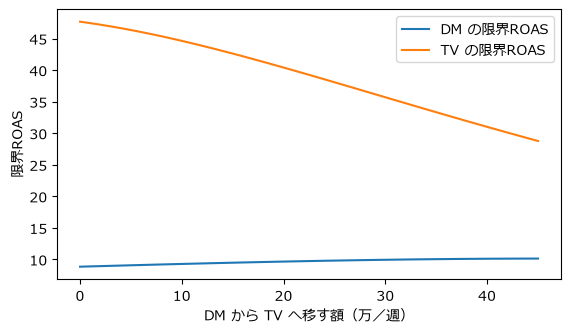

In [7]:
moves2 = np.linspace(0, 45e4, 91)                     # DM から TV へ（0〜45万。DM は約47万）
total2, m_dm, m_tv = move_budget("DM", "TV", moves2)

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(moves2 / 1e4, m_dm, label="DM の限界ROAS")
ax.plot(moves2 / 1e4, m_tv, label="TV の限界ROAS")
ax.set_xlabel("DM から TV へ移す額（万／週）")
ax.set_ylabel("限界ROAS")
ax.legend()
print(f"いま：DM {m_dm[0]:.1f}、TV {m_tv[0]:.1f} ／ 45万を移した後：DM {m_dm[-1]:.1f}、TV {m_tv[-1]:.1f}")
print(f"45万を移した後の TV：{(x_now[channels.index('TV')] + 45e4) / 1e4:.0f}万／週（いまの約5.5倍）")

**読み方**：2本の線は交わりません。DM をほとんど全部 TV に移しても、まだ TV の限界ROASのほうが高いままです。
計算どおりなら「DM をやめて、全部 TV に」が答えになります。

しかし、これを実行する人はいないでしょう。TV をいまの5倍以上にするのは現実的ではなく、モデルの推定にも幅があります。
だから実務の最適化には、必ず**制約**をつけます。

## 2. 7チャネルで最適化する

### 2-1. 設定

本家のノートブックと同じ設定にします。

- **対象**：テスト期間（直近26週）の広告費。「この26週の予算を、どう配分し直せばよかったか」を考えます
- **総額**：テスト期間の週平均の合計（約116万／週）を変えない
- **制約**：各チャネルの増減は、いまの週平均の **±50%まで**

**なぜ制約をつけるのか**　制約なしで計算すると、「いちばん効率の良いチャネルに全額」のような極端な答えが出ます。本家は、±50%にとどめる理由を4つ挙げています。

1. **実行できる範囲**：契約や広告枠の都合で、予算を急に大きく動かすことはできない
2. **リスク管理**：モデルの予測が外れたときの損失を抑える
3. **承認の得やすさ**：ほどほどの変更のほうが、社内で通しやすい
4. **モデルの不確かさ**：区間が広いチャネルがあるので、控えめに動かすのが賢明

本家は「最初は20〜30%から始めて、モデルへの信頼が高まったら広げるチームもある」とも書いています。制約の幅は、予算を決める人と相談して決めるものです。

### 2-2. 最適化を実行する

`scipy` の `minimize` を使います。「総額が同じ」「各チャネルは±50%以内」という条件のもとで、7チャネルの貢献の期待値がいちばん大きくなる配分を探します。

- `minimize` は「最小にする」道具なので、貢献にマイナスをつけて渡します
- `method="SLSQP"` は、条件つきの最適化で定番の方法です（本家も同じ方法を使っています）

総額：いま 116.3万／週 → 最適化後 116.3万／週


,いまの配分（万／週）,最適化後（万／週）,倍率,いまの限界ROAS,最適化後の限界ROAS
DM,46.57,23.28,0.50,8.84,9.75
折込,4.10,6.15,1.50,57.79,56.15
新聞,1.05,0.53,0.50,15.76,15.77
ラジオ,13.02,17.59,1.35,28.56,24.68
TV,10.04,15.06,1.50,47.66,46.34
ソーシャル,16.53,16.20,0.98,24.37,24.58
ディスプレイ,24.99,37.49,1.50,41.56,30.32


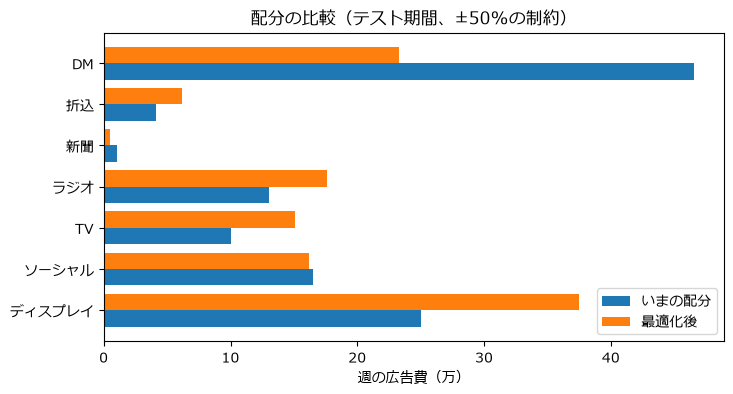

In [8]:
def optimize_budget(x_start, flex, objective=expected_total):
    # x_start：いまの週の広告費（7チャネル）、flex：増減の上限（0.5 なら ±50%）
    budget = x_start.sum()
    result = minimize(
        lambda x: -objective(x) / 1e6,                                        # 貢献の合計を最大にする
        x0=x_start,
        method="SLSQP",
        bounds=[((1 - flex) * v, (1 + flex) * v) for v in x_start],            # 各チャネルは ±flex 以内
        constraints=[{"type": "eq", "fun": lambda x: (x.sum() - budget) / budget}],   # 総額は変えない
        options={"ftol": 1e-10, "maxiter": 1000},
    )
    assert result.success, result.message
    return result.x

FLEX = 0.5
x_opt = optimize_budget(x_now, FLEX)

plan = pd.DataFrame({
    "いまの配分（万／週）": x_now / 1e4,
    "最適化後（万／週）": x_opt / 1e4,
    "倍率": x_opt / x_now,
    "いまの限界ROAS": marginal_roas(x_now).mean(axis=0),
    "最適化後の限界ROAS": marginal_roas(x_opt).mean(axis=0),
}, index=channels)
print(f"総額：いま {x_now.sum() / 1e4:.1f}万／週 → 最適化後 {x_opt.sum() / 1e4:.1f}万／週")

fig, ax = plt.subplots(figsize=(8, 4))
ypos = np.arange(len(channels))
ax.barh(ypos + 0.2, x_now / 1e4, height=0.4, label="いまの配分")
ax.barh(ypos - 0.2, x_opt / 1e4, height=0.4, label="最適化後")
ax.set_yticks(ypos)
ax.set_yticklabels(channels)
ax.invert_yaxis()
ax.set_xlabel("週の広告費（万）")
ax.set_title("配分の比較（テスト期間、±50%の制約）")
ax.legend()
plan.round(2)

**読み方**

- **減らす**：DM と新聞は下限いっぱい（0.5倍）
- **増やす**：折込・TV・ディスプレイは上限いっぱい（1.5倍）。ラジオは1.35倍
- **ほぼそのまま**：ソーシャル（0.98倍）

**限界ROASの列で、原理を確かめます。**

- **ラジオとソーシャル**は上限にも下限にも当たっていません。最適化後の限界ROASは、どちらも約25でそろっています。1章の原理どおりです
- **折込・TV・ディスプレイ**は、最適化後も限界ROASが高いまま（30〜56）。もっと増やしたいのに、上限で止められています
- **DM と新聞**は限界ROASが低いまま（10〜16）。もっと減らしたいのに、下限で止められています
- ディスプレイは、増やしたことで限界ROASが42 → 30に下がりました。7チャネルの中では、頭打ちの影響がいちばん見えているチャネルです

> **本家との比較**：本家の倍率は、TV・ラジオ・ディスプレイ・折込が1.5、DM・新聞が0.5、ソーシャルが0.86です。
> こちらはラジオ1.35、ソーシャル0.98で、この2つだけ少し違います。どちらも限界ROASが近いチャネル同士なので、わずかな推定の違いで入れ替わります。全体の方向は同じです。
> 本家は PyMC-Marketing の最適化機能を使っています。この教材は中身が見えるように `scipy` で直接計算しました（ライブラリの機能は、この環境では10分以上かかります）。

## 3. 最適化したら、どれだけ増えるか

配分案ができました。次に知りたいのは「それで売上はいくら増えるのか」と「それはどのくらい確かなのか」です。

第5回と同じ考え方で、4,000組のパラメータそれぞれについて「いまの配分」と「最適化後」の貢献を計算し、増加率を4,000個出します。

### 3-1. テスト期間（毎週同じ額を出す前提）

広告の貢献の増加率： 中央値 +21.2%（94%の範囲 -2.1% 〜 +37.2%）、増える確率 96%
26週での増加額（億）： 中央値 +1.77（94%の範囲 -0.19 〜 +3.76）


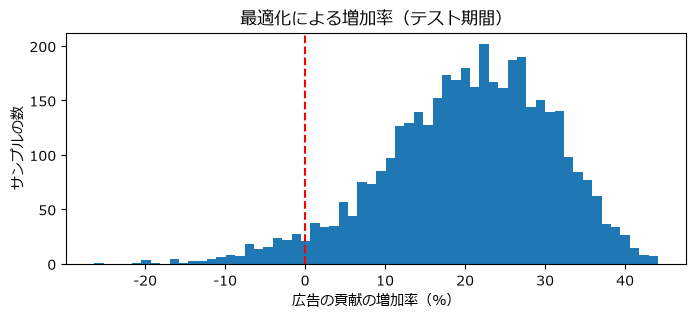

In [9]:
def summarize(v, pct=True):
    lo, med, hi = np.quantile(v, [0.03, 0.5, 0.97])
    if pct:
        return f"中央値 {med:+.1%}（94%の範囲 {lo:+.1%} 〜 {hi:+.1%}）、増える確率 {(v > 0).mean():.0%}"
    return f"中央値 {med:+.2f}（94%の範囲 {lo:+.2f} 〜 {hi:+.2f}）"

c_now = weekly_contribution(x_now).sum(axis=1)       # 4,000組：いまの配分での週あたりの貢献
c_opt = weekly_contribution(x_opt).sum(axis=1)       # 4,000組：最適化後
uplift_test = c_opt / c_now - 1
gain_26w = (c_opt - c_now) * 26 / 1e8                # 26週分の増加額（億）

print("広告の貢献の増加率：", summarize(uplift_test))
print("26週での増加額（億）：", summarize(gain_26w, pct=False))

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(uplift_test * 100, bins=60)
ax.axvline(0, color="red", linestyle="--")
ax.set_xlabel("広告の貢献の増加率（%）")
ax.set_ylabel("サンプルの数")
ax.set_title("最適化による増加率（テスト期間）");

**読み方**

- 広告の貢献は、中央値で**約21%増える**見込みです。本家もテスト期間について「約20%の増加」と書いており、一致します
- 94%の範囲は約 −2%〜+37%。**増える確率は96%**です
- 金額では、26週で約1.8億の増加（範囲は約 −0.2億〜+3.8億）

総額を変えずに、配分を変えただけの効果です。

**「96%の確率で増える」をどう読むか**　25回に1回くらいは、配分を変えたことで逆に減る可能性がある、ということでもあります。
ただし、減る場合の幅は小さく（最悪でも数%）、増える場合の幅は大きい。期待値で見て有利な賭けです。

### 3-2. 学習期間で確かめる（本家と同じ方法）

本家は、次の方法でも効果を確かめています。「**学習期間の183週、もしこの倍率で配分していたら、売上はどうなっていたか**」。

1. 学習期間の毎週の広告費に、チャネルごとの倍率をかける
2. 総額が元と同じになるように、全体を調整する
3. その広告費で、モデルに売上を計算し直させる
4. 元の広告費での計算結果と比べる

3-1 と違い、週ごとの広告費の上下（年末に集中など）や adstock もそのまま反映されます。

総額：元 3.252 億 / 配分し直した後 3.252 億


Sampling: [y]


Sampling: [y]


広告の貢献の増加率： 中央値 +27.1%（94%の範囲 +2.4% 〜 +46.7%）、増える確率 98% ／平均 +26.5%
売上全体の増加率　： 中央値 +9.3%（94%の範囲 -1.4% 〜 +20.4%）、増える確率 95% ／平均 +9.4%


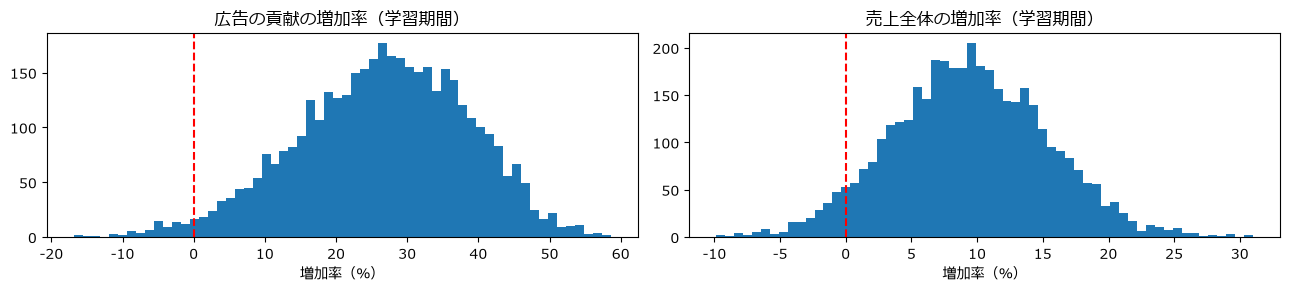

In [10]:
multiplier = x_opt / x_now

X_train_opt = X_train.copy()
X_train_opt[channels] = X_train[channels] * multiplier                                   # 1. 倍率をかける
X_train_opt[channels] *= X_train[channels].sum().sum() / X_train_opt[channels].sum().sum()   # 2. 総額をそろえる
print("総額：元", round(X_train[channels].sum().sum() / 1e8, 3), "億 / 配分し直した後", round(X_train_opt[channels].sum().sum() / 1e8, 3), "億")

def predict(X, seed):
    return mmm.sample_posterior_predictive(
        X, var_names=["y", "channel_contribution"], extend_idata=False, combined=False,
        random_seed=seed, compile_kwargs=FAST, progressbar=False,
    )

pred_now = predict(X_train, SEED)             # 3. 元の広告費で計算
pred_opt = predict(X_train_opt, SEED + 1)     #    配分し直した広告費で計算

contrib_now = pred_now["channel_contribution"].sum(dim=("date", "channel")).to_numpy().ravel()
contrib_opt = pred_opt["channel_contribution"].sum(dim=("date", "channel")).to_numpy().ravel()
sales_now = pred_now["y"].sum(dim="date").to_numpy().ravel()
sales_opt = pred_opt["y"].sum(dim="date").to_numpy().ravel()

uplift_contrib = contrib_opt / contrib_now - 1      # 4. 比べる
uplift_sales = sales_opt / sales_now - 1

print("広告の貢献の増加率：", summarize(uplift_contrib), f"／平均 {uplift_contrib.mean():+.1%}")
print("売上全体の増加率　：", summarize(uplift_sales), f"／平均 {uplift_sales.mean():+.1%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3))
for ax, v, title in [(axes[0], uplift_contrib, "広告の貢献の増加率"), (axes[1], uplift_sales, "売上全体の増加率")]:
    ax.hist(v * 100, bins=60)
    ax.axvline(0, color="red", linestyle="--")
    ax.set_xlabel("増加率（%）")
    ax.set_title(f"{title}（学習期間）")
plt.tight_layout()

**読み方**

- **広告の貢献**：平均 +26.5%、増える確率98%。本家は「約26%、増える確率は96.7%以上」で、一致します
- **売上全体**：平均 +9.4%、増える確率95%。本家は「約10%」で、こちらも一致します

**なぜ売上全体では小さくなるのか**　売上の約6割はベース（広告と関係なく得られる売上）で、配分を変えても動かないからです。
広告の貢献が27%増えても、売上全体で見れば1割弱の増加になります。それでも、総額を増やさずに売上が1割近く増えるなら、大きな成果です。

**なぜテスト期間（21%）より大きいのか**　学習期間は、限界ROASの低い DM の比重がテスト期間より大きく、移せる予算が多かったためと考えられます（私の解釈です）。

**この数字の注意点**

- これは「過去にこう配分していたら」という仮の計算で、実際に試した結果ではありません。本家も「これは学習期間内の推定で、実際の成果は違う可能性がある」と書いています
- 売上全体の増加率は、94%の範囲が約 −1%〜+20% と広い。予測の誤差（第6回で見た、週ごとに当たらない部分）が混ざるためです

## 4. 配分案そのものは、どのくらい確かか

ここまでの配分案は、4,000組の**平均**がいちばん良くなるように決めました。
しかし第5回で見たとおり、ROAS の上位3チャネルの順位は五分五分でした。パラメータの組が変われば、最適な配分も変わるはずです。

そこで、4,000組から300組を選び、**1組ごとに最適化をやり直します**。300通りの「最適な配分」がどれだけ散らばるかを見ます。

,平均で決めた倍率,上限（1.5倍）になった割合,下限（0.5倍）になった割合,増やす結果になった割合
DM,0.50,0.00,0.26,0.08
折込,1.50,0.79,0.15,0.81
新聞,0.50,0.42,0.53,0.46
ラジオ,1.35,0.41,0.19,0.53
TV,1.50,0.74,0.09,0.80
ソーシャル,0.98,0.34,0.18,0.47
ディスプレイ,1.50,0.51,0.03,0.78


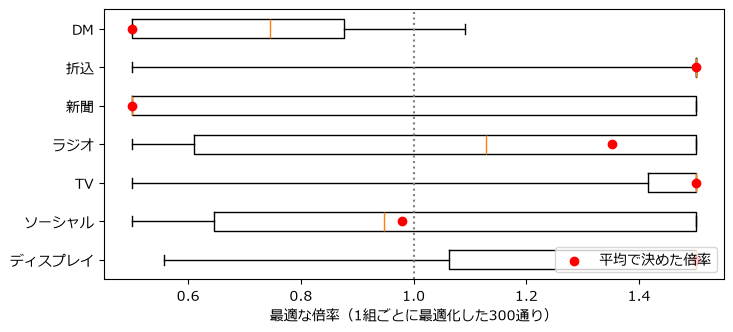

In [11]:
rng = np.random.default_rng(SEED)
picked = rng.choice(beta.shape[0], size=300, replace=False)

def total_for_one(i):
    # i 番目のパラメータの組だけで計算した、貢献の合計
    def f(x):
        u = lam[i] * x / channel_scale
        return (beta[i] * (1 - np.exp(-u)) / (1 + np.exp(-u)) * target_scale).sum()
    return f

mult_each = np.array([optimize_budget(x_now, FLEX, objective=total_for_one(i)) / x_now for i in picked])   # 300 × 7

each = pd.DataFrame({
    "平均で決めた倍率": multiplier,
    "上限（1.5倍）になった割合": (mult_each > 1.49).mean(axis=0),
    "下限（0.5倍）になった割合": (mult_each < 0.51).mean(axis=0),
    "増やす結果になった割合": (mult_each > 1.0).mean(axis=0),
}, index=channels)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot([mult_each[:, j] for j in range(len(channels))], vert=False, tick_labels=channels, whis=(3, 97), showfliers=False)
ax.scatter(multiplier, np.arange(1, len(channels) + 1), color="red", zorder=3, label="平均で決めた倍率")
ax.axvline(1, color="gray", linestyle=":")
ax.invert_yaxis()
ax.set_xlabel("最適な倍率（1組ごとに最適化した300通り）")
ax.legend(loc="lower right")
each.round(2)

**読み方**（赤い点が、2章で決めた配分案。箱とひげが、300通りの散らばり）

| チャネル | 300通りのうち「増やす」になった割合 | 判断 |
|---|---|---|
| DM | 8% | **減らす**のは、ほぼ確か（92%が減らす） |
| 折込・TV・ディスプレイ | 78〜81% | **増やす**のは、かなり確か |
| ラジオ・ソーシャル・新聞 | 46〜53% | 五分五分。増やすか減らすか、決められない |

- 2章の配分案は「DMを減らし、折込・TV・ディスプレイを増やす」が骨格でした。この骨格は、パラメータの組が変わっても8〜9割で同じ結論になります
- 一方、「ラジオを1.35倍に」という部分は根拠が弱い。300通りの中では、上限にも下限にも散らばっています
- 新聞は上限と下限に真っ二つに割れていますが、週1万円ほどしか使っていないので、どちらでも結果にほとんど影響しません

**提案への生かし方**：確かな部分（DM → 折込・TV・ディスプレイ）だけを動かし、決められない部分（ラジオ・ソーシャル・新聞）は現状のままにする。
これなら「なぜその配分なのか」を聞かれたときに、根拠を示せます。

## 5. 🧪 実験：制約の幅を変える

`FLEX_TEST` を変えて、配分と増加率がどう変わるかを確かめてください。

- `0.2`：±20%まで（控えめ）
- `0.5`：±50%まで（本家と同じ）
- `1.0`：0〜2倍まで（大胆）

In [12]:
FLEX_TEST = 0.2

x_test_opt = optimize_budget(x_now, FLEX_TEST)
up = weekly_contribution(x_test_opt).sum(axis=1) / weekly_contribution(x_now).sum(axis=1) - 1

result = pd.DataFrame({
    "いまの配分（万／週）": x_now / 1e4,
    "最適化後（万／週）": x_test_opt / 1e4,
    "倍率": x_test_opt / x_now,
    "学習期間の最大（万／週）": channel_scale / 1e4,
}, index=channels)
result["過去の最大を超える"] = np.where(x_test_opt > channel_scale, "超える", "")

print(f"制約 ±{FLEX_TEST:.0%}")
print("広告の貢献の増加率：", summarize(up))
print("減る場合の大きさ（下から3%）：", f"{np.quantile(up, 0.03):+.1%}")
result.round(2)

制約 ±20%
広告の貢献の増加率： 中央値 +9.1%（94%の範囲 -0.1% 〜 +15.3%）、増える確率 97%
減る場合の大きさ（下から3%）： -0.1%


,いまの配分（万／週）,最適化後（万／週）,倍率,学習期間の最大（万／週）,過去の最大を超える
DM,46.57,37.25,0.80,240.99,
折込,4.10,4.92,1.20,59.01,
新聞,1.05,0.84,0.80,219.85,
ラジオ,13.02,14.96,1.15,43.56,
TV,10.04,12.05,1.20,110.01,
ソーシャル,16.53,16.29,0.99,57.34,
ディスプレイ,24.99,29.99,1.20,69.58,


**読み方**（制約の幅を変えた結果）

| 制約 | 増加率の中央値 | 94%の範囲 | 増える確率 | 配分の主な変化 |
|---|---|---|---|---|
| ±10% | +2.0% | −0.1%〜+4.8% | 96% | 折込・TV を1.1倍 |
| ±20% | +9.1% | −0.1%〜+15.3% | 97% | DM 0.8倍、折込・TV・ディスプレイ 1.2倍 |
| ±50% | +21.2% | −2.1%〜+37.2% | 96% | DM 0.5倍、折込・TV・ディスプレイ 1.5倍 |
| ±100% | +38.1% | −8.4%〜+70.0% | 95% | DM と新聞をゼロ、折込・TV を2倍 |

- 制約をゆるめるほど、期待できる増加は大きくなります
- 同時に、**外れたときの損失も大きくなります**。範囲の下端は、±20%で −0.1%、±50%で −2.1%、±100%で −8.4%
- 増える確率は、どの幅でも95〜97%でほとんど変わりません。変わるのは「どれだけ賭けるか」です

±100%では DM をゼロにする案が出ます。しかし第5回で見たとおり、DM の ROAS が1を超える確率は92%で、やめれば売上を失う可能性が高い。
しかも、DM を完全に止めた週はデータにありません。**データのない領域ほど、モデルの予測は仮定に頼ります。**

表のどの案でも、過去の最大費用は超えていません（「過去の最大を超える」の列）。超える案が出たときは、とくに注意が必要です。

## 6. 提案するときの注意

最適化の結果は、数字がはっきり出るので説得力があります。だからこそ、前提と限界を一緒に伝えます。

**この計算が置いている前提**

1. **毎週同じ額を出す**（3-1）。実際の出稿は週ごとに上下します。本家も、季節性の強い広告では配分の時期も考える必要があると注意しています
2. **チャネル同士は影響し合わない**。TVを見て検索する、といった相乗効果は入っていません
3. **効果は時期によって変わらない**。学習期間の関係が、これからも続くと仮定しています
4. **曲線の曲がり方（λ）は、ほぼ事前の仮定**（第5回）。大きく増やした先の予測ほど、データではなく仮定で決まっています
5. **第6回で見たとおり、広告効果の推定そのものが実験で確かめられていない**

**提案の組み立て方**

本家は、結論の部分で次のような進め方を勧めています。この教材の結果に当てはめます。

| 段階 | 内容 |
|---|---|
| 1. 小さく始める | 確かな部分だけを、±20%の範囲で動かす（DM を2割減らし、折込・TV・ディスプレイを2割増やす）。見込みは広告の貢献 +9%前後 |
| 2. 実験で確かめる | 一部の地域だけで配分を変え、変えなかった地域と売上を比べる |
| 3. モデルを更新する | 実験の結果と新しいデータを入れて、学習し直す（四半期〜半年ごと） |
| 4. 幅を広げる | 予測どおりなら、制約を±30%、±50%と広げていく |

**言い方の例**

- ❌「最適化すると売上が10%増えます」
- ✅「同じ予算のまま配分を変えると、売上が増える可能性が95%あります。増加の中心は1割弱ですが、ほぼ変わらない可能性も、2割増える可能性もあります。まず2割の範囲で動かして、結果を確かめながら広げることをお勧めします」

## 7. 小課題

自分の答えを考えてから「答えを見る」を開いてください。

**課題1**　経営層が「制約なしで最適化した結果を見せてほしい。それをそのまま実行したい」と言っています。5章のセルで `FLEX_TEST = 1.0` を試したうえで、どう答えますか。

<details>
<summary>答えを見る</summary>

結果を見せることはできますが、そのまま実行することは勧めません。

- ±100%では、DM と新聞をゼロにし、折込と TV を2倍にする案が出ます。期待できる増加は約38%と大きい
- しかし、範囲の下端は約 −8%まで広がります。外れたときの損失が、±20%の案（−0.1%）とは桁違いです
- DM をゼロにした週は過去になく、その領域の予測はモデルの仮定に頼っています
- 契約や広告枠の都合で、実際には急に2倍・ゼロにはできないことが多い

「期待値は大きいが、確かめられていない賭けです。段階的に進めれば、同じ方向に、ずっと小さなリスクで進めます」と伝えます。

</details>

**課題2**　2章の結果で、ラジオとソーシャルの最適化後の限界ROASは、どちらも約25でそろっていました。一方、TV は約46のままです。なぜ TV はそろわないのでしょうか。

<details>
<summary>答えを見る</summary>

TV は上限（1.5倍）に当たっているからです。

制約がなければ、最適化は TV にもっと予算を移し、TV の限界ROASが他のチャネルと同じになるまで続けます。
しかし±50%の制約で止められたので、限界ROASが高いまま残りました。「まだ増やす価値があるのに、制約で止まっている」状態です。

限界ROASがそろうのは、上限にも下限にも当たっていないチャネル同士だけです。
逆に言うと、**最適化後に限界ROASが高いまま残っているチャネルは、制約をゆるめたときに次に増やす候補**になります。

</details>

**課題3**　4章で、ラジオを「増やす」結果になったのは300通りのうち53%でした。提案書に「ラジオを1.35倍に」と書くべきでしょうか。

<details>
<summary>答えを見る</summary>

書かないほうがよいでしょう。53%は五分五分で、増やすべきか減らすべきか、データからは決まっていません。
1.35倍という数字は、4,000組を平均したときにたまたま出た値で、根拠は弱い。

提案では、8〜9割の確かさがある部分（DM を減らし、折込・TV・ディスプレイを増やす）だけを動かし、ラジオは現状維持とします。
「なぜラジオは変えないのか」と聞かれたら、「今回のデータでは判断できなかったため」と答えます。分からないことを動かさないのも、分析に基づく判断です。

</details>

**課題4**　最適化で「広告の貢献 +27%」という結果が出ました。この数字が大きく外れるとしたら、どんな場合でしょうか。3つ挙げてください。

<details>
<summary>答えの例を見る</summary>

- **広告効果の推定がずれている場合**。DM の効果が実際はもっと大きければ、減らしたことで損をします。ROAS の区間は広く、実験でも確かめていません
- **増やしたチャネルが、思ったより早く頭打ちになる場合**。曲線の曲がり方は、ほぼ事前の仮定でした
- **チャネル同士に相乗効果がある場合**。たとえば DM が来店のきっかけを作り、ほかの広告がそれを後押ししているなら、DM を減らすとほかの広告の効果も下がります。モデルはこれを考慮していません
- **市場の状況が変わる場合**。競合の動き、景気、媒体の値上げなどで、過去の関係が続かなくなる
- **モデルに入っていない要因を、広告の効果として数えている場合**（値引きなど）

どれも、実験と段階的な実行で早めに気づけるものです。

</details>

## 8. まとめ

- **問い**：総額を変えずに、配分だけを変えて、広告の貢献を最大にする
- **原理**：限界ROASの高いチャネルへ、低いチャネルから移す。限界ROASがそろったところで止める
- 制約がないと極端な答えになる（DM をほぼ全部 TV へ）。実務では必ず**制約**をつける（本家は±50%）
- **結果（±50%）**：DM と新聞を0.5倍、折込・TV・ディスプレイを1.5倍、ラジオ1.35倍、ソーシャルほぼそのまま。本家とほぼ同じ
- **効果**：テスト期間で広告の貢献 +21%（増える確率96%）。学習期間に当てはめると広告の貢献 +27%、売上全体 +9%。本家の「約20%」「約26%」「約10%」と一致
- **配分案の確かさ**：「DM を減らし、折込・TV・ディスプレイを増やす」は8〜9割で同じ結論。ラジオ・ソーシャル・新聞は五分五分
- 制約をゆるめるほど、期待できる増加も、外れたときの損失も大きくなる
- **提案**：確かな部分だけを小さく動かす → 実験で確かめる → モデルを更新する → 幅を広げる

**次回（第8回）**：全体の振り返り。経営層向けに「MMMで何が分かるか」を1枚にまとめます。